In [2]:
%load_ext autoreload
%autoreload 2

Question 1

We will be using python for numerically solving for and plotting Black-Scholes IV, as excel would require lots of inefficient goal seeks. We start by importing packages and loading the options data into a pandas dataframe and adding a tau column which is the annualised maturity.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

raw = pd.read_excel("AMZN_options.xlsx", sheet_name="options", header=None)

options = []

for col in range(1, 6):
    days = raw.iloc[1, col]
    strikes = raw.iloc[3:16, col]
    prices = raw.iloc[17:30, col]

    for strike, price in zip(strikes, prices):
        options.append({
            "days": days,
            "strike": strike,
            "price": price
        })

options = pd.DataFrame(options)
options["tau"] = options["days"]/365
options.head()

,days,strike,price,tau
0,14.0,230.0,30.62,0.038356
1,14.0,235.0,25.67,0.038356
2,14.0,240.0,20.87,0.038356
3,14.0,245.0,16.25,0.038356
4,14.0,250.0,11.94,0.038356


We define the Black-Scholes formula for a call option and let it return the price of the option given parameters. We will use this function when solving for the IV numerically.

In [4]:
def bs_call(S, K, r, tau, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)

    return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)


We also define the function that numerically solves for and returns the IV that makes C_modelprice - C_marketprice = 0.

We use SciPy's brentq to solve for IV, giving it an interval of [0.01%;300%] in annual volatility.

In [5]:
def implied_vol(S, K, r, tau, price):
    def pricing_error(sigma):
        return bs_call(S, K, r, tau, sigma) - price

    return brentq(pricing_error, 0.0001, 3.0)

We run a first test and get an IV of sigma=0.335 which seems reasonable.

If we plug this into our Black-Scholes function we should expect to get back the observed market price. Rounded to two decimals we get exactly the same price, so we conclude that our code works.

In [6]:
S=260
r=0.05
test = options.iloc[0]
iv = implied_vol(S, test["strike"], r, test["tau"],test["price"])
print(iv)

model_price = bs_call(S, test["strike"], r, test["tau"], iv)
print(f"Model price: {model_price:.2f}, market price: {test["price"]}")

0.33539714429219303
Model price: 30.62, market price: 30.62


Do the same for all option maturities and strikes and add list to options dataframe. We also define the forward price which is simply the cost of carrying the stock at r=5% and the log-moneyness

In [7]:
ivs = []

for _, option in options.iterrows():
    iv = implied_vol(
        S, option["strike"], r, option["tau"], option["price"]
    )
    ivs.append(iv)

options["iv"] = ivs
options.head()

,days,strike,price,tau,iv
0,14.0,230.0,30.62,0.038356,0.335397
1,14.0,235.0,25.67,0.038356,0.296830
2,14.0,240.0,20.87,0.038356,0.280666
3,14.0,245.0,16.25,0.038356,0.266925
4,14.0,250.0,11.94,0.038356,0.254658


In [8]:
options["forward"] = S * np.exp(r * options["tau"])
options["log_moneyness"] = np.log(options["strike"] / options["forward"])

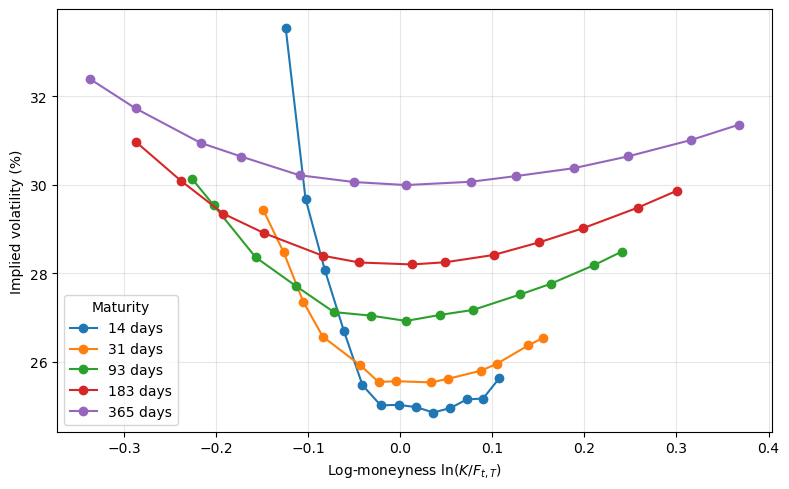

In [9]:
plt.figure(figsize=(8, 5))

for days, group in options.groupby("days"):
    group = group.sort_values("log_moneyness")
    plt.plot(
        group["log_moneyness"],
        100 * group["iv"],
        marker="o",
        label=f"{int(days)} days"
    )

plt.xlabel(r"Log-moneyness $\ln(K/F_{t,T})$")
plt.ylabel("Implied volatility (%)")
plt.legend(title="Maturity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We plot the IV per maturity and log-moneyness and observe various volatility smiles.

We notice that ITM call options are more expensive than a constant volatility Black-Scholes model would suggest. This means the market prices large price decreases as more likely than BS does, i.e. the left tail of the return distribution is fatter than under the lognormal distribution, which weights extreme scenarios less than we observe empirically. OTM calls are also somewhat more expensive, since a deep OTM call would need a very large increase in price to have a positive payoff, but the left wing is steeper than the right, so the smile is skewed towards low strikes.

We also notice that the shorter the maturity, the steeper the smile. For longer maturities this is best explained by e.g. volatility being stochastic and for very short maturities with very steep smiles this is best explained by jumps which can produce discontinuous price moves. If the market believes these models are more realistic it would show up in IV in the observed way.

We need to compute the BS deltas and vegas, and plot them as a function of log-moneyness for each maturity. For a call option on a non-dividend underlying, they are computed as
* delta: $\Delta^{call}=N(d_1)$
* vega: $\nu^{call}=S_t\phi(d_1)\sqrt{\tau}$

We define the functions that calculate these selected greeks

In [10]:
def bs_d1(S, K, r, tau, sigma):
    return (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))

def bs_delta(S, K, r, tau, sigma):
    d1 = bs_d1(S, K, r, tau, sigma)
    return norm.cdf(d1)

def bs_vega(S, K, r, tau, sigma):
    d1 = bs_d1(S, K, r, tau, sigma)
    return S * norm.pdf(d1) * np.sqrt(tau)

we calculate delta and vega for all options in the df, using the IVs as sigma input

In [11]:
options['delta'] = bs_delta(S, options['strike'], r, options['tau'], options['iv'])
options['vega'] = bs_vega(S, options['strike'], r, options['tau'], options['iv'])

options.head()

,days,strike,price,tau,iv,forward,log_moneyness,delta,vega
0,14.0,230.0,30.62,0.038356,0.335397,260.499109,-0.124520,0.973104,3.163700
1,14.0,235.0,25.67,0.038356,0.296830,260.499109,-0.103014,0.964156,4.012249
2,14.0,240.0,20.87,0.038356,0.280666,260.499109,-0.081961,0.935562,6.412964
3,14.0,245.0,16.25,0.038356,0.266925,260.499109,-0.061341,0.884841,9.893484
4,14.0,250.0,11.94,0.038356,0.254658,260.499109,-0.041139,0.802278,14.157656


We plot the delta and vega as functions of log-moneyness for the respective maturities

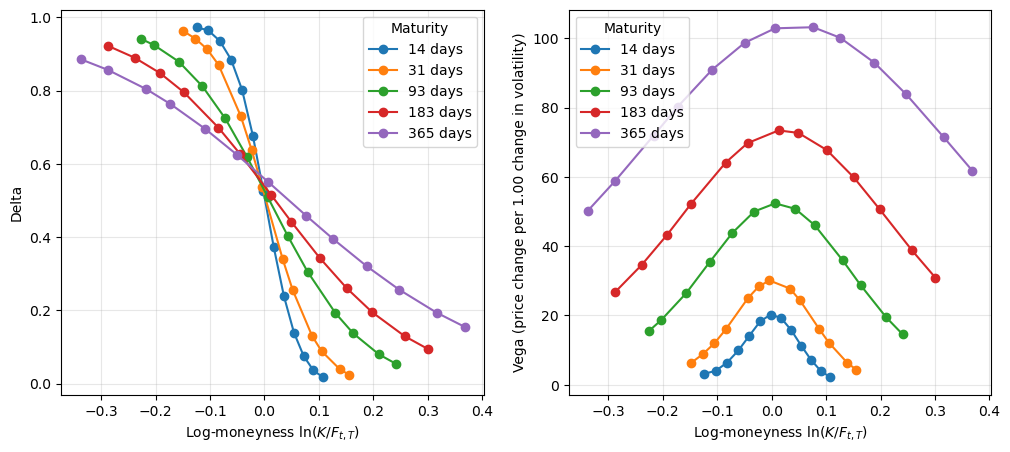

In [22]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

for days, group in options.groupby('days'):
    group = group.sort_values('log_moneyness')
    axes[0].plot(
        group['log_moneyness'],
        group['delta'],
        marker = 'o',
        label = f'{int(days)} days'
    )
    axes[1].plot(
        group['log_moneyness'],
        group['vega'],
        marker = 'o',
        label = f'{int(days)} days'
    )

axes[0].set_ylabel('Delta')
axes[1].set_ylabel('Vega (price change per 1.00 change in volatility)')
for ax in axes:
    ax.set_xlabel(r'Log-moneyness $\ln(K/F_{t,T})$')
    ax.grid(alpha = 0.3)
    ax.legend(title = 'Maturity')

plt.tight_layout
plt.show()

Delta is the sensitivity of the option price to the price of the underlying. It is positive across the whole grid, since $C_t^{BS}$ is strictly increasing in $S_t$. Intuitively, an increasing price of the underlying will only make a call option closer to being, or being further into, ITM territory. Delta falls from close to 1 for deep ITM calls to close to 0 for deep OTM calls. The transition is much steeper for short maturities, since there is little time for the stock price to cross the strike, meaning smaller movements in the underlying decide if it finishes above or below the strike.

Vega is the sensitivity of the option price to the volatility of the underlying, measured per unit change in $\sigma$. It is hump-shaped in log-moneyness, with its peak close to ATM strikes, where the outcome of the option is most uncertain. Vega is always positive, since $C_t^{BS}$ is strictly increasing in $\sigma$. Intuitively, an option holder benefits from higher volatility, since it makes large movements in both directions more likely. Potential gains from large upward movements outweigh the potential loss from large downward swings, which is limited to the option premium. This effect is largest for near ATM options, where small movements in the stock, helped on by larger volatility, decide whether the option expires with the underlying above the strike. Deep ITM and deep OTM options have low vega, since they are almost certain to finish in or out of the money regardless of a change in volatility. Vega is ceteris paribus increasing in maturity, since longer maturities give volatility more time to work. The same idea makes the humps wider with maturity, since strikes far from today's price are still reachable, as opposed to when time to expiration is short, and only strikes close to the money are in play.